# 06 · 노출 군집과 20종 전체의 공통 변동성 구간 연구

**연구 질문 (H4).** 05 에서 ETF 하나씩 찾은 다중 기간 변동성 국면이 다른 ETF 에서도 같은 시기에 나타나는가? 그 반복은 같은 지수를 추종하는 상품끼리의 '복제' 인가, 서로 다른 자산군에 걸친 '공통 충격' 인가?

**왜 필요한가.** 20종 가운데 4종(KODEX 200·TIGER 200·KODEX 레버리지·KODEX 인버스)은 같은 KOSPI200 지수에 노출돼 있다. 종목 수로만 세면 KOSPI200 사건 하나가 4건으로 보인다. 그래서 다음 두 기준을 함께 제시한다.
- **ETF 등가중**: 20종을 각각 1개로 센다.
- **노출 그룹 등가중**: 17개 그룹으로 센다. KOSPI200 4종은 1개 그룹이다.

**입력.**
- 05 의 인계 파일 `results/05_to_06.json` 을 쓴다. 결과 CSV 17개와 Git 제외 일별 파일 3개의 SHA256 을 대조한다.
- W1 의 사전 고정 노출 그룹(`category_exposure`)과 T11 공식 종목표의 자산유형(category)을 쓴다.
- 새로 상관계수 군집을 만들지 않는다. 전체 기간의 상관으로 묶으면 '과거 당시 이미 알았던 분류' 처럼 보이게 되기 때문이다.

**규칙 (계약 §4.7 [A-7]–[A-9]).**
- **교차 공통일**: 같은 날·같은 채널에서 05 의 후보일(≥3개 q 동시)을 가진 노출 그룹이 3개 이상인 날. 연속된 교차 공통일이 교차 공통 구간이다.
- **순위**: (최대 그룹 수, 지속일) 사전식이다. 종목 기준 비교에서는 (최대 ETF 수, 지속일)을 쓴다.
- **그룹 내부 공통일**: 같은 그룹의 2종 이상이 같은 날 후보인 날 (KOSPI200 만 해당).
- **민감도**: 미국 주식 2종(S&P500 선물·나스닥100)을 한 그룹으로 묶은 16개 그룹.

**해석 수준.** 자산 간 의존을 보존한 귀무보정을 하지 않았다. 따라서 모든 공통성은 **탐색적 기술**이다. 여러 그룹이 동시에 반응했다는 사실을 '유의한 시장 공통 국면' 으로 쓰지 않는다.

## 0. 실행 환경·동결 입력 검증

In [1]:
# 새 커널 첫 셀: BLAS 스레드를 NumPy 로드 전에 1로 고정해 결과를 결정적으로 만든다.
import os  # 환경변수 설정
import sys  # 인터프리터·모듈 경로 확인
from pathlib import Path  # 저장소 상대 경로

for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):  # 네 BLAS 계열 변수
    os.environ[key] = "1"  # 다중 스레드 합산 순서에 따른 비트 차이를 막는다
assert "numpy" not in sys.modules, "새 커널에서 첫 셀부터 실행해야 합니다"  # 숨은 커널 상태 금지
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs/t14_multihorizon_w2_v1.json").is_file())  # 저장소 루트 탐색
sys.path.insert(0, str(ROOT / "src"))  # 이 작업트리의 r2h 패키지를 우선 사용

import csv  # 보호 파일 SHA 목록
import importlib.metadata as metadata  # 설치 패키지 버전 조회
import json  # 설정·인계 파일
import platform  # Python 버전

import matplotlib.pyplot as plt  # 그림 기본 설정
import numpy as np  # 수치 배열
import pandas as pd  # 결과표
from IPython.display import Image, display  # 표·그림 출력
from matplotlib import font_manager  # 한글 글꼴 등록

# T12·W1 재현 환경과 같은 버전이어야 한다 (user-site 의 다른 numpy/pandas 를 잡으면 여기서 멈춘다).
EXPECTED_ENV = {"python": "3.12.3", "numpy": "2.5.4", "pandas": "3.0.6", "scipy": "1.18.1", "matplotlib": "3.11.2"}  # W2 고정 환경
ACTUAL_ENV = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scipy": metadata.version("scipy"), "matplotlib": metadata.version("matplotlib")}  # 실제 커널
assert ACTUAL_ENV == EXPECTED_ENV, f"실행 환경 불일치: {ACTUAL_ENV}"  # 버전 불일치는 재현 실패로 처리
assert "site-packages" in np.__file__ and ".local" not in np.__file__, np.__file__  # user-site 패키지 차단
FONT_FILE = Path("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")  # 한글 도판용 나눔고딕
assert FONT_FILE.is_file(), "한글 도판 렌더링을 위한 나눔고딕 파일이 없습니다"  # 글꼴 없으면 중단
font_manager.fontManager.addfont(str(FONT_FILE))  # matplotlib 글꼴 목록에 등록
plt.rcParams["font.family"] = [font_manager.FontProperties(fname=str(FONT_FILE)).get_name(), "DejaVu Sans"]  # 한글 우선·기호 대체
plt.rcParams["axes.unicode_minus"] = False  # 음수 기호 깨짐 방지
pd.set_option("display.width", 200)  # 표 줄바꿈 완화
pd.set_option("display.max_columns", 40)  # 열 생략 완화

from r2h.multihorizon.core import load_cfg, sha256  # W2 동결 설정·해시
from r2h.window_study.empirical import verify_frozen  # T12 동결 입력 검증 (W1 함수 재사용)
from r2h.window_study.simulation import load_cfg as load_w1_cfg  # W1 동결 설정

CFG = load_cfg(ROOT)  # W2 동결 설정 configs/t14_multihorizon_w2_v1.json
CFG_W1 = load_w1_cfg(ROOT)  # W1 동결 설정 configs/t13_window_study_v1.json (읽기만)
SOURCE = Path(os.environ.get("T12_FROZEN_ROOT", ROOT.parents[1] / "1016/R2H_T12_Final")).resolve()  # T12 종결 작업트리 (명시 경로)
assert SOURCE.name == "R2H_T12_Final" and SOURCE.is_dir(), SOURCE  # 새 위치의 형제 기본값이 아닌 실제 경로
assert Path(sys.modules["r2h"].__file__).resolve().is_relative_to((ROOT / "src").resolve())  # 다른 트리의 r2h 금지
FROZEN = verify_frozen(ROOT, SOURCE, CFG_W1)  # 00·01·02 노트북·원자료 22개·run manifest·일별 cache 20종 대조
# 계약·설정 동결 SHA 와 W1 보호 파일 153개를 대조한다.
FREEZE = [line.split(maxsplit=1) for line in (ROOT / "research/multihorizon_w2/CONTRACT_FREEZE_SHA256.txt").read_text().splitlines()[:3]]  # 동결 기록
for digest, name in FREEZE:  # 설정·계약·보호목록
    assert sha256(ROOT / name) == digest, f"동결 파일 변경: {name}"  # 결과를 본 뒤 규칙 변경 금지
PROTECTED = list(csv.DictReader(open(ROOT / "research/multihorizon_w2/W1_PROTECTED_SHA256.csv", encoding="utf-8")))  # 7205e91 시점 해시
CHANGED = [r["path"] for r in PROTECTED if sha256(ROOT / r["path"]) != r["sha256_at_7205e91"]]  # 바뀐 W1 파일
assert not CHANGED, f"W1 보호 파일 변경: {CHANGED}"  # W1 결과·노트북·계약은 읽기만
BASE = ROOT / "research/multihorizon_w2"  # W2 산출물 폴더
FIG = BASE / "figures"  # 그림 폴더
FIG.mkdir(parents=True, exist_ok=True)  # 없으면 만든다
print("작업트리:", ROOT)  # 실행 위치 기록
print("동결 T12:", FROZEN)  # 입력 검증 결과
print("W2 프로토콜:", CFG["protocol_version"], "| 설정 SHA256:", FREEZE[0][0][:16], "| 계약 SHA256:", FREEZE[1][0][:16])  # 동결 지문
print("W1 보호 파일", len(PROTECTED), "개 불변 · 실행 환경:", ACTUAL_ENV)  # 보호·환경 기록

작업트리: /home/sieg/projects-wsl/hongik_univ_26_2/SA/1017/R2H_MultiHorizon_Volatility_Regime
동결 T12: {'run_id': 'b_nb_20261016T181251', 'data_version': '5f20e3e0073b521a', 'notebook_count': 3, 'raw_sha_count': 22, 'daily_ticker_count': 20, 'source_root': '/home/sieg/projects-wsl/hongik_univ_26_2/SA/1016/R2H_T12_Final'}
W2 프로토콜: W2-lock-1 | 설정 SHA256: 9fa948762e9f7bfb | 계약 SHA256: 4dec1d40adc3d01a
W1 보호 파일 153 개 불변 · 실행 환경: {'python': '3.12.3', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy': '1.18.1', 'matplotlib': '3.11.2'}


## 1. 05 결과의 해시·설정 검증

05 가 남긴 결과 CSV·일별 파일·그림 색인의 SHA256 을 다시 계산해 인계 파일과 맞춘다. 설정·계약 SHA 도 05 와 같아야 한다.

In [2]:
# 05→06 인계 검증과 06 계산 (노출 군집·교차 공통 구간·그룹 내부·연도 요약·20종 전체 순위).
from r2h.multihorizon.stage06 import run_stage06  # 06 단계 계산 (src/r2h/multihorizon/stage06.py)

S06 = run_stage06(ROOT, CFG)  # 인계 해시 불일치면 여기서 멈춘다
H05 = S06["handoff05"]  # 05 인계 내용
assert H05["config_sha256"] == FREEZE[0][0] and H05["contract_sha256"] == FREEZE[1][0]  # 05 와 같은 동결 설정·계약
assert H05["environment"] == ACTUAL_ENV  # 05 와 같은 실행 환경
assert sha256(BASE / "results/05/figure_index_05.csv") == H05["figure_index_sha256"]  # 05 그림 색인 불변
print("05 인계 검증 통과: 결과", len(H05["results"]), "개 · 일별 파일", len(H05["work_files"]), "개 SHA256 일치")  # 결과

05 인계 검증 통과: 결과 12 개 · 일별 파일 3 개 SHA256 일치


## 2. ETF 유니버스와 유형, 기존 연구의 경제적 노출 그룹

In [3]:
# 노출 그룹 정의표: 주 17개 그룹, 미국 주식 묶음 민감도 16개 그룹, 명목 배수 (07 에서 사용).
EXPO = S06["exposure_groups"]  # 노출 그룹 표
display(EXPO)  # 20종 정의
print("주 노출 그룹 수:", EXPO.exposure_group.nunique(), "| 민감도 그룹 수:", EXPO.exposure_group_us.nunique(), "| 자산유형 수:", EXPO.category.nunique())  # 그룹 수
assert EXPO.exposure_group.nunique() == 17 and EXPO.exposure_group_us.nunique() == 16  # 계약 [A-7]
display(EXPO.groupby("category").ticker.apply(list).to_frame("ETF"))  # 자산유형별 구성

,ticker,name,category,exposure_group,exposure_group_us,nominal_multiplier
0,069500,KODEX 200,broad_market,KOSPI200_동일노출,KOSPI200_동일노출,1.0
1,102110,TIGER 200,broad_market,KOSPI200_동일노출,KOSPI200_동일노출,1.0
2,229200,KODEX 코스닥150,broad_market,229200,229200,1.0
3,122630,KODEX 레버리지,leveraged_inverse,KOSPI200_동일노출,KOSPI200_동일노출,2.0
4,114800,KODEX 인버스,leveraged_inverse,KOSPI200_동일노출,KOSPI200_동일노출,-1.0
5,091230,TIGER 반도체,sector,091230,091230,1.0
6,091170,KODEX 은행,sector,091170,091170,1.0
7,091180,KODEX 자동차,sector,091180,091180,1.0
8,305540,TIGER 2차전지테마,theme,305540,305540,1.0
9,143860,TIGER 헬스케어,sector,143860,143860,1.0


주 노출 그룹 수: 17 | 민감도 그룹 수: 16 | 자산유형 수: 9


,ETF
category,
broad_market,"[069500, 102110, 229200, 219480, 133690, 192090]"
commodity,"[132030, 261220]"
currency,[261240]
leveraged_inverse,"[122630, 114800]"
money_market,[153130]
rates,[148070]
sector,"[091230, 091170, 091180, 143860, 117680]"
strategy,[161510]
theme,[305540]


**표 해석.**
- 노출 그룹(17개)과 자산유형(9개)은 다른 축이다.
  - 자산유형 `broad_market` 에는 KOSPI200·코스닥150·미국 S&P500·나스닥100·중국 CSI300 이 함께 있다. 이들은 서로 다른 시장이다.
  - 노출 그룹은 **같은 지수를 추종하는 상품끼리만** 묶는다.
- 레버리지(2배)와 인버스(−1배)도 KOSPI200 그룹에 넣는다.
  - 분산 채널(V, D)은 수익률의 부호와 무관하다.
  - 배수가 m 이면 분산은 m² 배이지만, 그 ETF 자기 과거 분위 U 는 배수에 거의 영향을 받지 않는다.

## 3. 군집 중복 집계 검사

KOSPI200 4종이 같은 날 모두 후보이면 ETF 수는 4 만큼 늘고, 노출 그룹 수는 1 만 늘어야 한다. 실제 일별 표에서 확인한다.

In [4]:
# 중복 집계 검사: (n_etf − n_group) 은 그날 후보인 KOSPI200 종목 수 − 1 (최소 0) 과 같아야 한다.
DAILY = S06["cross_daily_counts"]  # 날짜 × 채널 집계
OV = S06["overlap"]  # 05 일별 중첩 표
k = OV[OV.ticker.isin(CFG["exposure_kospi200"]) & OV.overlap_candidate_day].groupby(["channel", "date"]).ticker.nunique()  # 날짜별 KOSPI200 후보 수
chk = DAILY.set_index(["channel", "date"]).join(k.rename("k200"), how="left").fillna({"k200": 0})  # 결합
assert ((chk.n_etf - chk.n_group) == (chk.k200 - 1).clip(lower=0)).all()  # 그룹 수는 KOSPI200 을 한 번만 센다
print("중복 집계 검사 통과:", len(chk), "개 날짜×채널. KOSPI200 4종 동시 후보일 수 =", int((chk.k200 == 4).sum()))  # 결과

중복 집계 검사 통과: 7612 개 날짜×채널. KOSPI200 4종 동시 후보일 수 = 563


## 4. KOSPI200 동일 노출 ETF 4종 비교 — 군집 내부 구간 중첩

channel            CONTRACTION  EXPANSION  HIGH_LEVEL  LOW_LEVEL
ticker_a ticker_b                                               
069500   102110          0.800      0.932       0.991      0.914
         114800          0.562      0.817       0.963      0.788
         122630          0.800      0.867       0.963      0.896
102110   114800          0.625      0.758       0.953      0.806
         122630          0.750      0.867       0.972      0.916
114800   122630          0.529      0.754       0.926      0.792

,구간,네종목_동시,지속일_중앙
channel,,,
CONTRACTION,9,6,1.0
EXPANSION,12,8,1.5
HIGH_LEVEL,11,9,3.0
LOW_LEVEL,20,14,1.5


,exposure_group,channel,interval_start,interval_end,duration_trading_days,max_members,members_ever,start_year,year_status
0,KOSPI200_동일노출,EXPANSION,2021-01-19,2021-01-19,1,2,"102110,122630",2021,PRIMARY
1,KOSPI200_동일노출,EXPANSION,2022-01-28,2022-02-07,4,4,"069500,102110,114800,122630",2022,PRIMARY
2,KOSPI200_동일노출,EXPANSION,2022-09-14,2022-09-15,2,3,"069500,114800,122630",2022,PRIMARY
3,KOSPI200_동일노출,EXPANSION,2023-11-06,2023-11-09,4,4,"069500,102110,114800,122630",2023,PRIMARY
4,KOSPI200_동일노출,EXPANSION,2023-11-14,2023-11-14,1,3,"069500,102110,114800",2023,PRIMARY
5,KOSPI200_동일노출,EXPANSION,2023-11-16,2023-11-16,1,4,"069500,102110,114800,122630",2023,PRIMARY
6,KOSPI200_동일노출,EXPANSION,2024-08-02,2024-09-02,21,4,"069500,102110,114800,122630",2024,PRIMARY
7,KOSPI200_동일노출,EXPANSION,2024-09-04,2024-09-12,7,4,"069500,102110,114800,122630",2024,PRIMARY
8,KOSPI200_동일노출,EXPANSION,2024-09-26,2024-09-26,1,4,"069500,102110,114800,122630",2024,PRIMARY
9,KOSPI200_동일노출,EXPANSION,2025-04-07,2025-04-25,15,4,"069500,102110,114800,122630",2025,PRIMARY


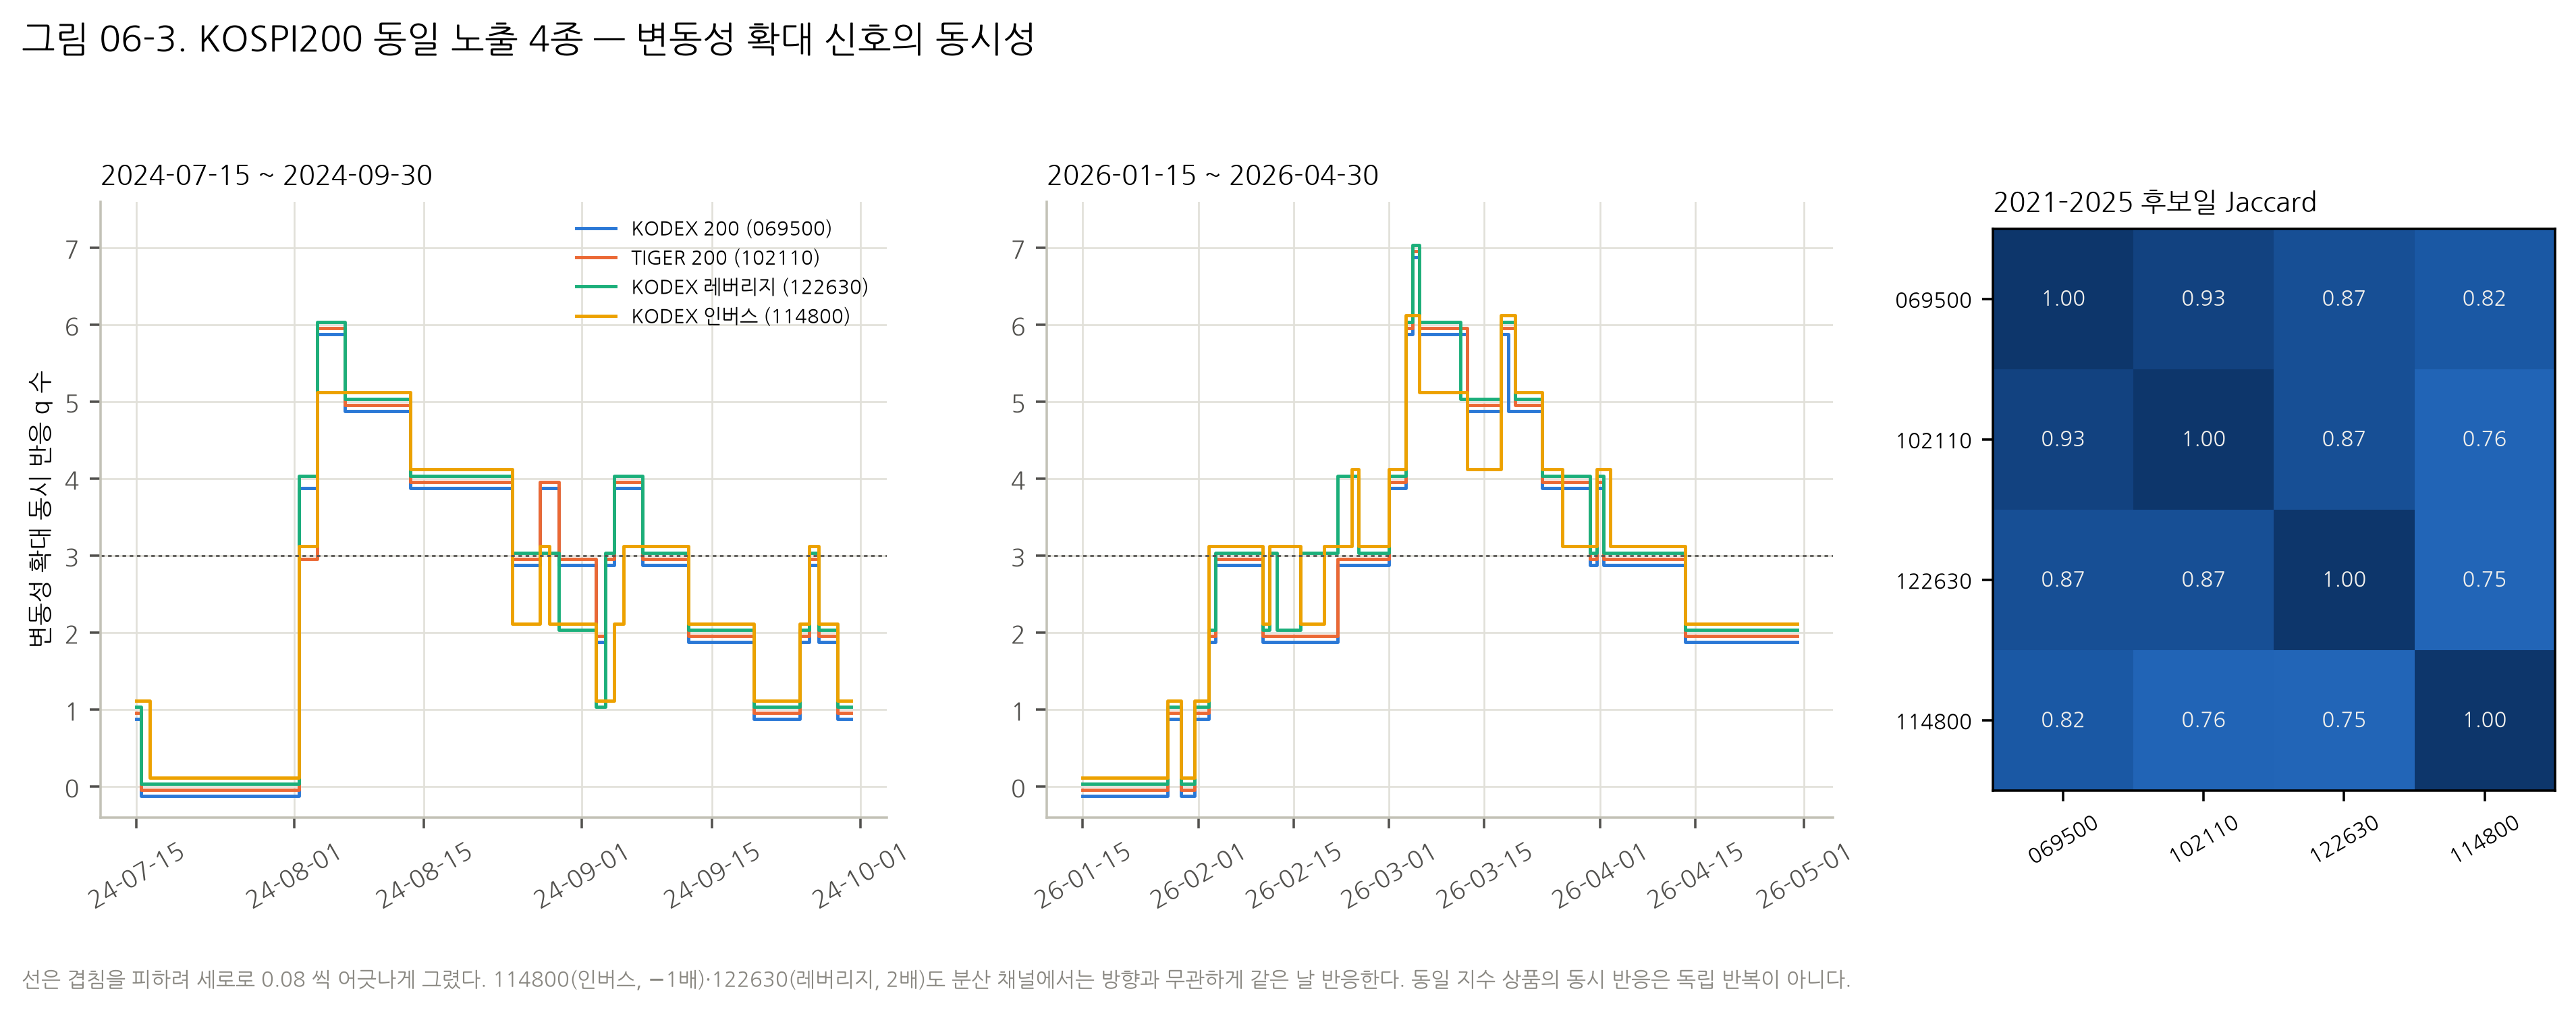

In [5]:
# 그룹 내부: 2021–2025 후보일 Jaccard (쌍별) 와 ≥2종 동시 후보 구간.
WJ = S06["within_group_pair_jaccard"]  # KOSPI200 쌍 Jaccard
display(WJ.pivot_table(index=["ticker_a", "ticker_b"], columns="channel", values="jaccard").round(3))  # 쌍 × 채널
WI = S06["within_group_intervals"]  # 그룹 내부 구간
display(WI[WI.year_status == "PRIMARY"].groupby("channel").agg(구간=("duration_trading_days", "size"), 네종목_동시=("max_members", lambda s: int((s == 4).sum())), 지속일_중앙=("duration_trading_days", "median")))  # 2021–25 요약
display(WI[(WI.channel == "EXPANSION") & (WI.year_status == "PRIMARY")].reset_index(drop=True))  # 확대 채널 내부 구간 전체
from r2h.multihorizon import figures as F  # W2 그림 함수

NAMES = EXPO.set_index("ticker").name.to_dict()  # 코드 → 이름
FIG_FILES = []  # 그림 파일 목록
FIG_FILES += F.kospi200_case(OV, WJ, NAMES, CFG["exposure_kospi200"], [("2024-07-15", "2024-09-30"), ("2026-01-15", "2026-04-30")], FIG, "06-3")  # 그림 06-3
display(Image(filename=str(FIG_FILES[-2]), width=950))  # 표시

**해석 (그림 06-3).**
- 2021–2025 후보일 Jaccard 는 고변동성 수준에서 0.93–0.99, 확대에서 0.75–0.93 이다. 같은 지수를 추종하는 네 상품은 사실상 같은 신호를 낸다.
- 인버스 114800 이 들어간 쌍의 일치도가 가장 낮다 (확대 0.75–0.82). 원인으로는 상품 구조(−1배 일별 재조정, 영(0) 수익률 90일로 많음)를 생각할 수 있다. 이번에 검증하지는 않았다.
- 2024-08 확대 구간은 네 종목 모두 2024-08-02 에 시작한다. 끝나는 날은 08-23(인버스) ~ 09-02 로 조금 다르다.
- 2026-02 ~ 04 구간은 레버리지 122630 이 02-19 로 가장 먼저 시작한다. 069500·102110 의 02-23 보다 2거래일 빠르다.
- **결론의 범위:** 이 4종의 동시 반응은 독립된 4번의 관측이 아니라 **한 노출의 반복 측정**이다. 아래 모든 교차 집계는 이 4종을 한 그룹으로 센다.

## 5. 군집 간 공통성 — 노출이 다른 ETF 쌍의 일치도

In [6]:
# 모든 ETF 쌍 (190쌍) 의 2021–2025 후보일 Jaccard: 같은 노출 그룹 / 같은 자산유형 / 둘 다 다름.
PJ = S06["all_pair_jaccard"]  # 쌍 × 채널
tab = PJ.assign(관계=np.where(PJ.same_group, "같은 노출 그룹", np.where(PJ.same_category, "다른 노출·같은 자산유형", "다른 자산유형"))).groupby(["channel", "관계"]).jaccard.agg(["size", "median", "max"]).round(3)  # 관계별 요약
display(tab)  # 같은 노출 ≫ 같은 유형 > 다른 유형
for ch in ("HIGH_LEVEL", "EXPANSION"):  # 두 주 채널
    top = PJ[(PJ.channel == ch) & ~PJ.same_group].sort_values("jaccard", ascending=False).head(6).copy()  # 다른 노출 쌍 상위
    top["a"], top["b"] = top.ticker_a.map(NAMES), top.ticker_b.map(NAMES)  # 이름
    print(ch, "— 노출이 다른 쌍 중 일치도 상위")  # 제목
    display(top[["ticker_a", "a", "ticker_b", "b", "same_category", "n_both", "jaccard"]].round(3).reset_index(drop=True))  # 표

size  median    max
channel     관계                                
CONTRACTION 같은 노출 그룹          6   0.688  0.800
            다른 노출·같은 자산유형    25   0.031  0.081
            다른 자산유형         159   0.000  0.167
EXPANSION   같은 노출 그룹          6   0.842  0.932
            다른 노출·같은 자산유형    25   0.176  0.574
            다른 자산유형         159   0.111  0.583
HIGH_LEVEL  같은 노출 그룹          6   0.963  0.991
            다른 노출·같은 자산유형    25   0.112  0.452
            다른 자산유형         159   0.089  0.508
LOW_LEVEL   같은 노출 그룹          6   0.851  0.916
            다른 노출·같은 자산유형    25   0.078  0.302
            다른 자산유형         159   0.051  0.390

HIGH_LEVEL — 노출이 다른 쌍 중 일치도 상위


,ticker_a,a,ticker_b,b,same_category,n_both,jaccard
0,148070,KIWOOM 국고채10년,153130,KODEX 단기채권,False,233,0.508
1,133690,TIGER 미국나스닥100,219480,KODEX 미국S&P500선물(H),True,52,0.452
2,091170,KODEX 은행,161510,PLUS 고배당주,False,42,0.429
3,229200,KODEX 코스닥150,305540,TIGER 2차전지테마,False,84,0.400
4,069500,KODEX 200,091230,TIGER 반도체,False,73,0.317
5,148070,KIWOOM 국고채10년,261240,KODEX 미국달러선물,False,117,0.315


EXPANSION — 노출이 다른 쌍 중 일치도 상위


,ticker_a,a,ticker_b,b,same_category,n_both,jaccard
0,091170,KODEX 은행,161510,PLUS 고배당주,False,49,0.583
1,133690,TIGER 미국나스닥100,219480,KODEX 미국S&P500선물(H),True,35,0.574
2,102110,TIGER 200,229200,KODEX 코스닥150,True,34,0.493
3,069500,KODEX 200,229200,KODEX 코스닥150,True,34,0.493
4,069500,KODEX 200,133690,TIGER 미국나스닥100,True,37,0.474
5,102110,TIGER 200,133690,TIGER 미국나스닥100,True,37,0.474


**해석.**
- 노출이 다른 ETF 쌍의 후보일 일치도 중앙값은 낮다. 고변동성 0.09–0.11, 확대 0.11–0.18 이다. 같은 노출 그룹(0.96·0.84)과는 차이가 크다.
- 그럼에도 노출이 다른 쌍 중 일치도가 높은 조합이 있다.
  - 고변동성: 국고채10년–단기채권 0.51 (금리), 미국 S&P500–나스닥100 0.45
  - 확대: 은행–고배당 0.58, 미국 2종 0.57
  - 미국 2종을 한 그룹으로 묶는 민감도는 이 관찰 때문에 사전에 넣어 두었다 (§8).
- 일치도가 높다고 같은 원인이라는 뜻은 아니다. 두 계열은 같은 날짜 축을 공유하고 지속성이 강해, 우연히 겹치는 날도 많다.

## 6. 전체 ETF 공통 구간 — 노출 그룹 기준 교차 공통 구간

그룹 기준(≥3/17)  종목 기준(≥3/20)
channel     year_status                                  
CONTRACTION PARTIAL_NON_BLIND             8             9
            PILOT                         6             8
            PRIMARY                      17            25
EXPANSION   PARTIAL_NON_BLIND             8             8
            PILOT                         3             4
            PRIMARY                      23            25
HIGH_LEVEL  PARTIAL_NON_BLIND             5             2
            PILOT                         7             8
            PRIMARY                      46            47
LOW_LEVEL   PILOT                         4             5
            PRIMARY                      43            45

,channel,interval_start,interval_end,duration_trading_days,max_count,max_n_etf,max_n_category,year_status,rank_in_channel,groups_ever
0,HIGH_LEVEL,2020-02-24,2020-05-08,51,17,20,9,PILOT,1,"091170,091180,091230,117680,132030,133690,1438..."
1,HIGH_LEVEL,2026-01-21,2026-09-15,160,13,16,8,PARTIAL_NON_BLIND,2,"091170,091180,091230,117680,132030,133690,1438..."
2,HIGH_LEVEL,2025-04-07,2025-05-26,33,13,16,6,PRIMARY,3,"091180,091230,117680,132030,133690,143860,1920..."
3,HIGH_LEVEL,2024-08-05,2024-08-23,14,10,13,5,PRIMARY,4,"091170,091180,091230,117680,133690,143860,1615..."
4,HIGH_LEVEL,2020-06-15,2020-06-23,7,8,11,5,PILOT,5,"091170,091180,091230,117680,161510,229200,3055..."
5,HIGH_LEVEL,2022-09-07,2022-12-07,62,7,7,6,PRIMARY,6,"091230,117680,132030,133690,148070,153130,1920..."
6,HIGH_LEVEL,2023-11-02,2023-11-23,16,7,10,6,PRIMARY,7,"091230,117680,148070,153130,229200,261240,3055..."
7,HIGH_LEVEL,2022-05-30,2022-07-19,35,6,6,5,PRIMARY,8,"091230,117680,133690,148070,153130,219480,2292..."


,channel,interval_start,interval_end,duration_trading_days,max_count,max_n_etf,max_n_category,year_status,rank_in_channel,groups_ever
0,EXPANSION,2026-01-26,2026-04-13,52,14,17,8,PARTIAL_NON_BLIND,1,"091170,091180,091230,117680,132030,143860,1480..."
1,EXPANSION,2024-08-02,2024-09-02,21,11,14,6,PRIMARY,2,"091170,091180,091230,117680,133690,143860,1480..."
2,EXPANSION,2020-03-19,2020-03-26,6,11,14,7,PILOT,3,"091170,091180,091230,117680,143860,153130,1615..."
3,EXPANSION,2025-04-07,2025-05-07,20,10,13,6,PRIMARY,4,"091170,091180,132030,133690,143860,161510,1920..."
4,EXPANSION,2020-03-13,2020-03-17,3,7,9,6,PILOT,5,"091170,091180,132030,148070,161510,261220,KOSP..."
5,EXPANSION,2026-06-08,2026-06-10,3,7,10,4,PARTIAL_NON_BLIND,5,"091170,091180,091230,143860,161510,229200,KOSP..."
6,EXPANSION,2026-06-12,2026-06-16,3,7,10,5,PARTIAL_NON_BLIND,5,"091170,091230,132030,143860,161510,229200,KOSP..."
7,EXPANSION,2024-02-01,2024-02-22,14,6,6,4,PRIMARY,8,"091170,091180,091230,153130,161510,192090"


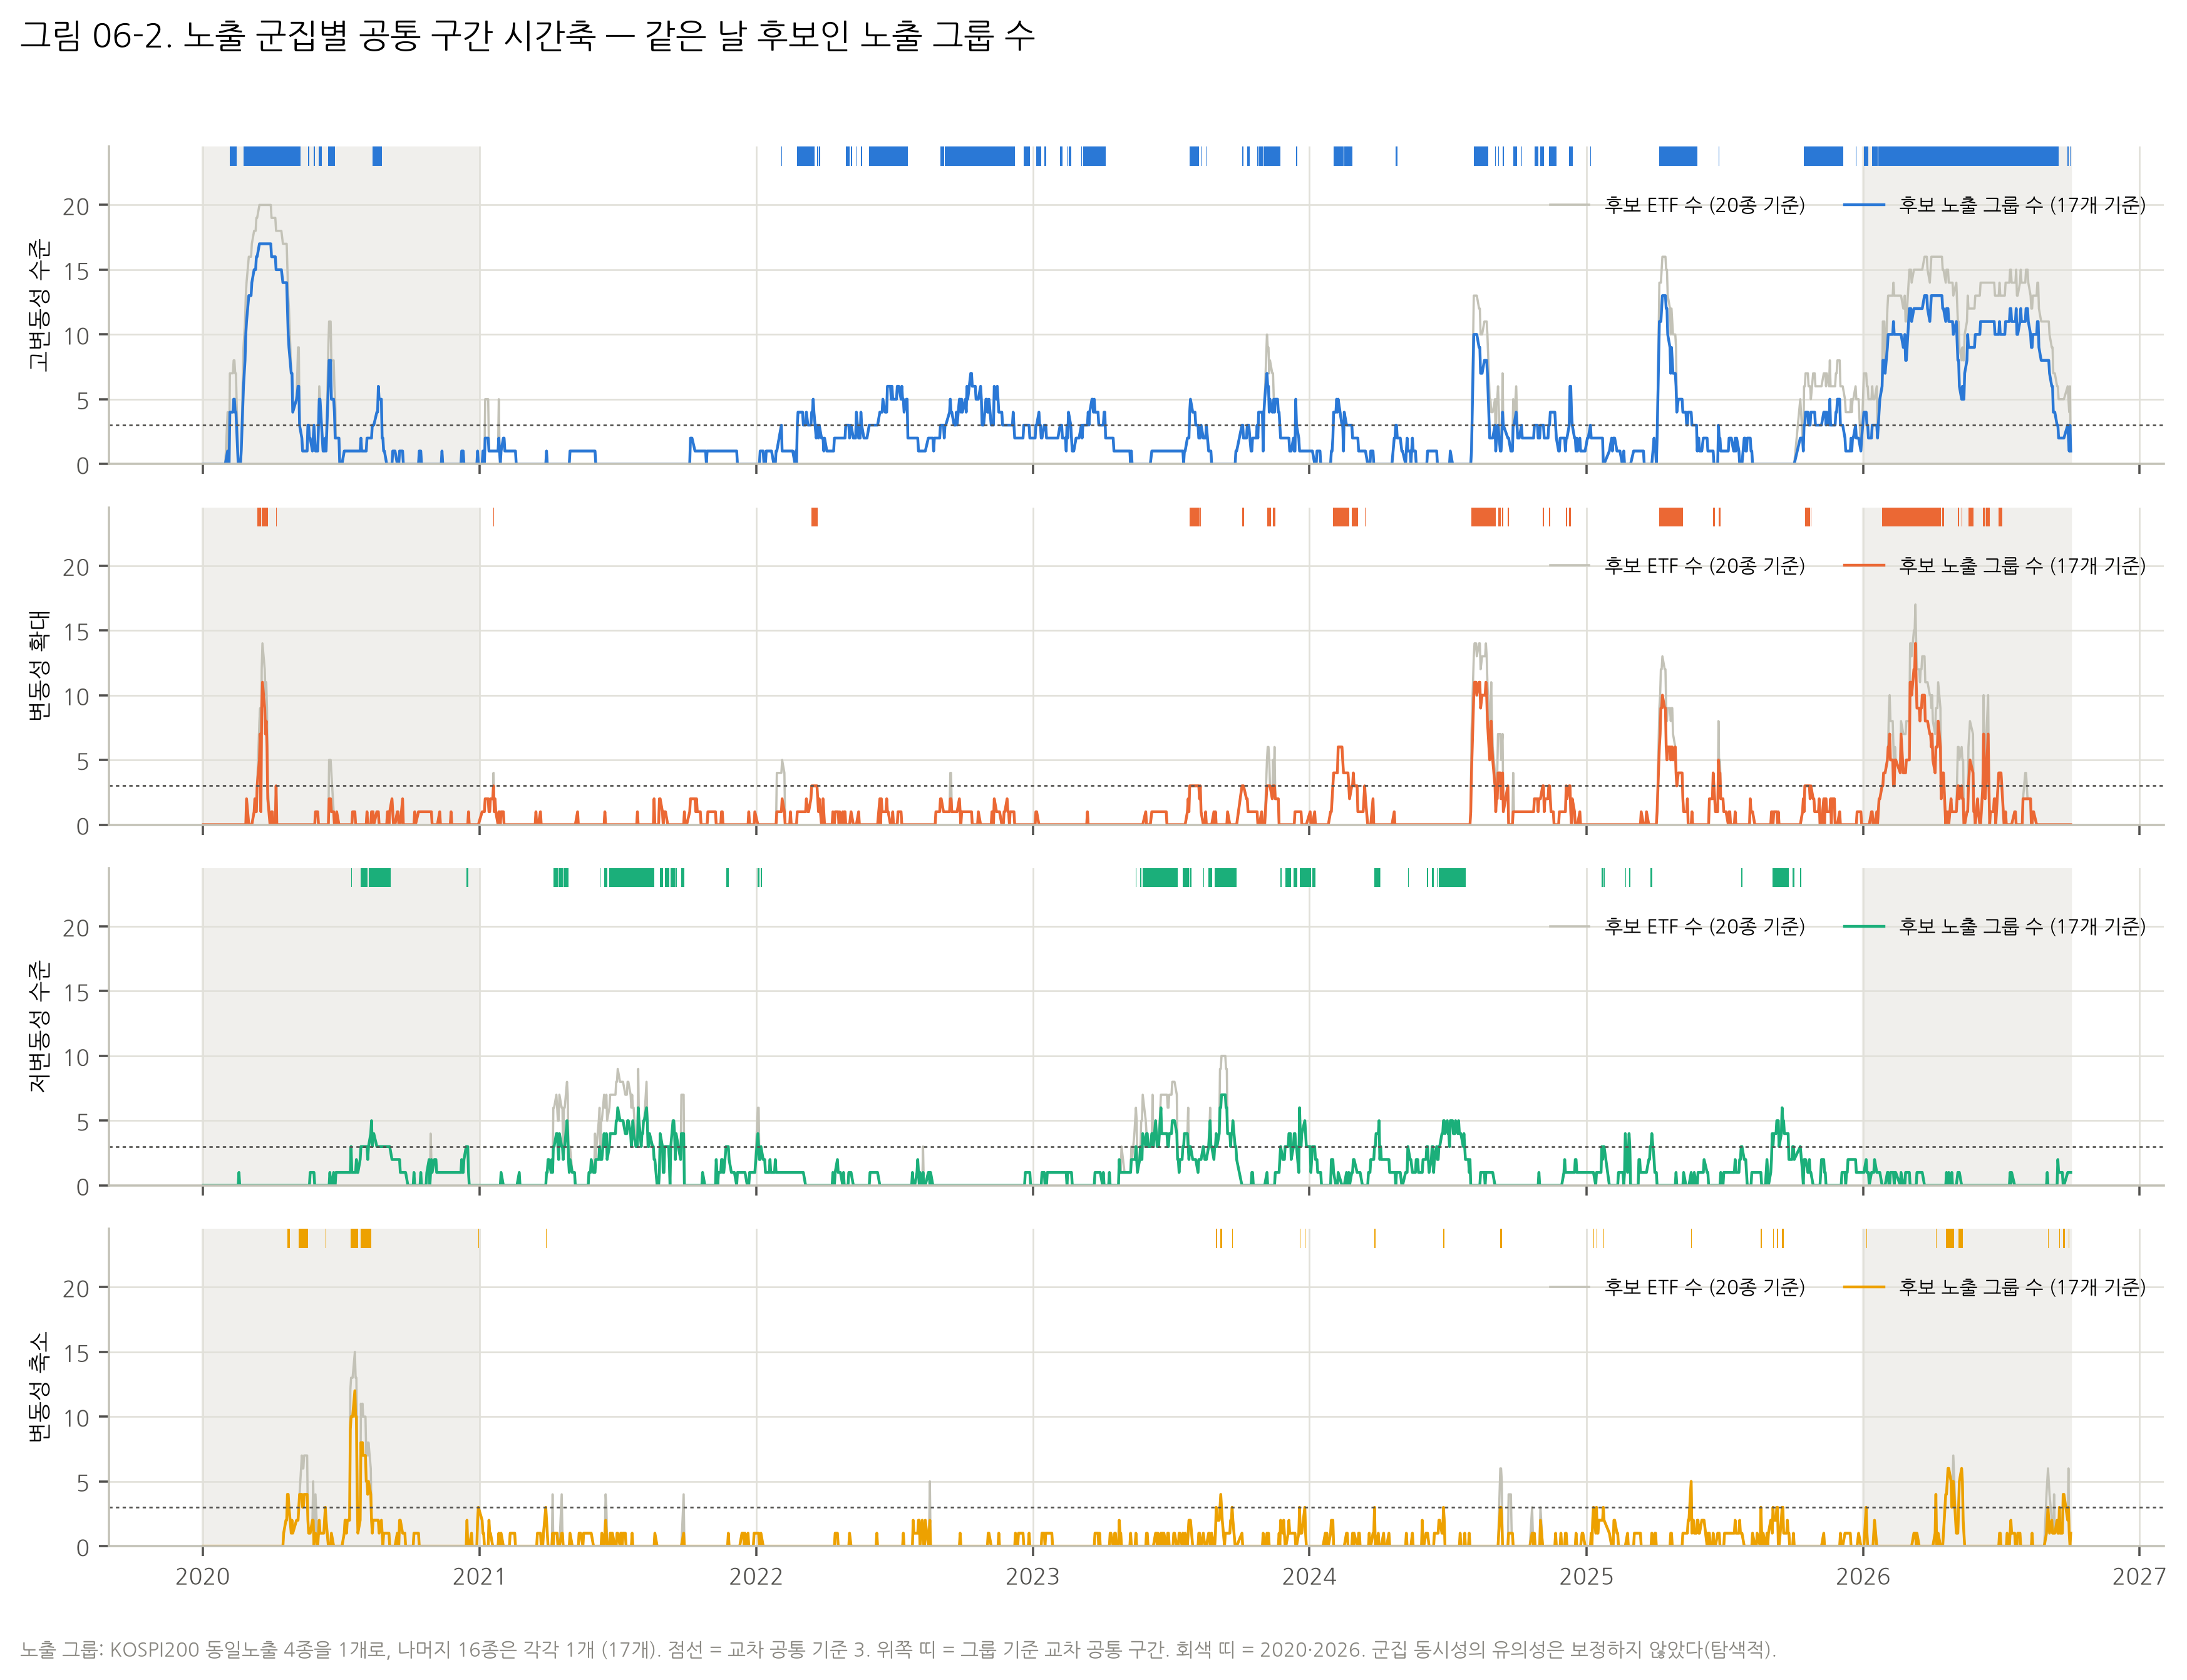

In [7]:
# 그룹 기준 교차 공통 구간 (≥3 노출 그룹 동시 후보) 과 종목 기준 (≥3 ETF) 의 개수·상위 구간.
CG = S06["cross_intervals_group"]  # 그룹 기준
CE = S06["cross_intervals_etf"]  # 종목 기준
cnt = pd.concat({"그룹 기준(≥3/17)": CG.groupby(["channel", "year_status"]).size(), "종목 기준(≥3/20)": CE.groupby(["channel", "year_status"]).size()}, axis=1).fillna(0).astype(int)  # 개수 비교
display(cnt)  # 연도 지위별 개수
cols = ["channel", "interval_start", "interval_end", "duration_trading_days", "max_count", "max_n_etf", "max_n_category", "year_status", "rank_in_channel", "groups_ever"]  # 표 열
for ch in ("HIGH_LEVEL", "EXPANSION"):  # 두 주 채널
    display(CG[CG.channel == ch].head(8)[cols].reset_index(drop=True))  # 채널 전체 순위 상위 8
FIG_FILES += F.group_count_timeline(DAILY, CG, FIG, "06-2", 17)  # 그림 06-2
display(Image(filename=str(FIG_FILES[-2]), width=950))  # 표시

**해석 (그림 06-2).**

1. **시장 공통 확대 사건 (2021–2025).** 노출 그룹 다수가 같은 날 변동성 확대 후보가 된 구간은 두 개가 두드러진다.
   - 2024-08-02 ~ 09-02 (21일): 최대 11/17 그룹, 14개 ETF
   - 2025-04-07 ~ 05-07 (20일): 최대 10/17 그룹, 13개 ETF
   - 이 밖에는 6개 그룹 이하다.
2. **그룹 기준 전체 1위는 2026 구간이다.**
   - 확대: 2026-01-26 ~ 04-13, 52일, 14 그룹
   - 고변동성: 2020 파일럿(2020-02-24 ~ 05-08, 17/17 그룹 전부), 그다음 2026-01-21 ~ 09-15 (160일, 13 그룹)
   - 두 해 모두 주 해석 연도 밖이다.
3. **채권·통화가 주도한 2022 고변동성 공통 구간.**
   - 2022-09-07 ~ 12-07 (62일, 7개 그룹)과 2022-05-30 ~ 07-19 (35일, 6개 그룹)에는 KOSPI200 그룹이 **없다**.
   - 대신 국고채10년·단기채권·달러선물·미국 주식·반도체·2차전지 등이 함께 반응했다.
   - 주식형이 주도한 2024-08·2025-04 와는 구성이 다른 공통 국면이다.
4. **개별 사건과의 대비.** 05 의 확대 7/7 구간인 차이나CSI300(2024-09-27 ~ 11-14)은, 같은 기간 후보 그룹이 최대 3개에 그친다. 다중 기간으로는 가장 강한 확대 가운데 하나지만, 시장 공통 사건은 아니다.

## 7. ETF × 거래일 히트맵과 연도별 분포

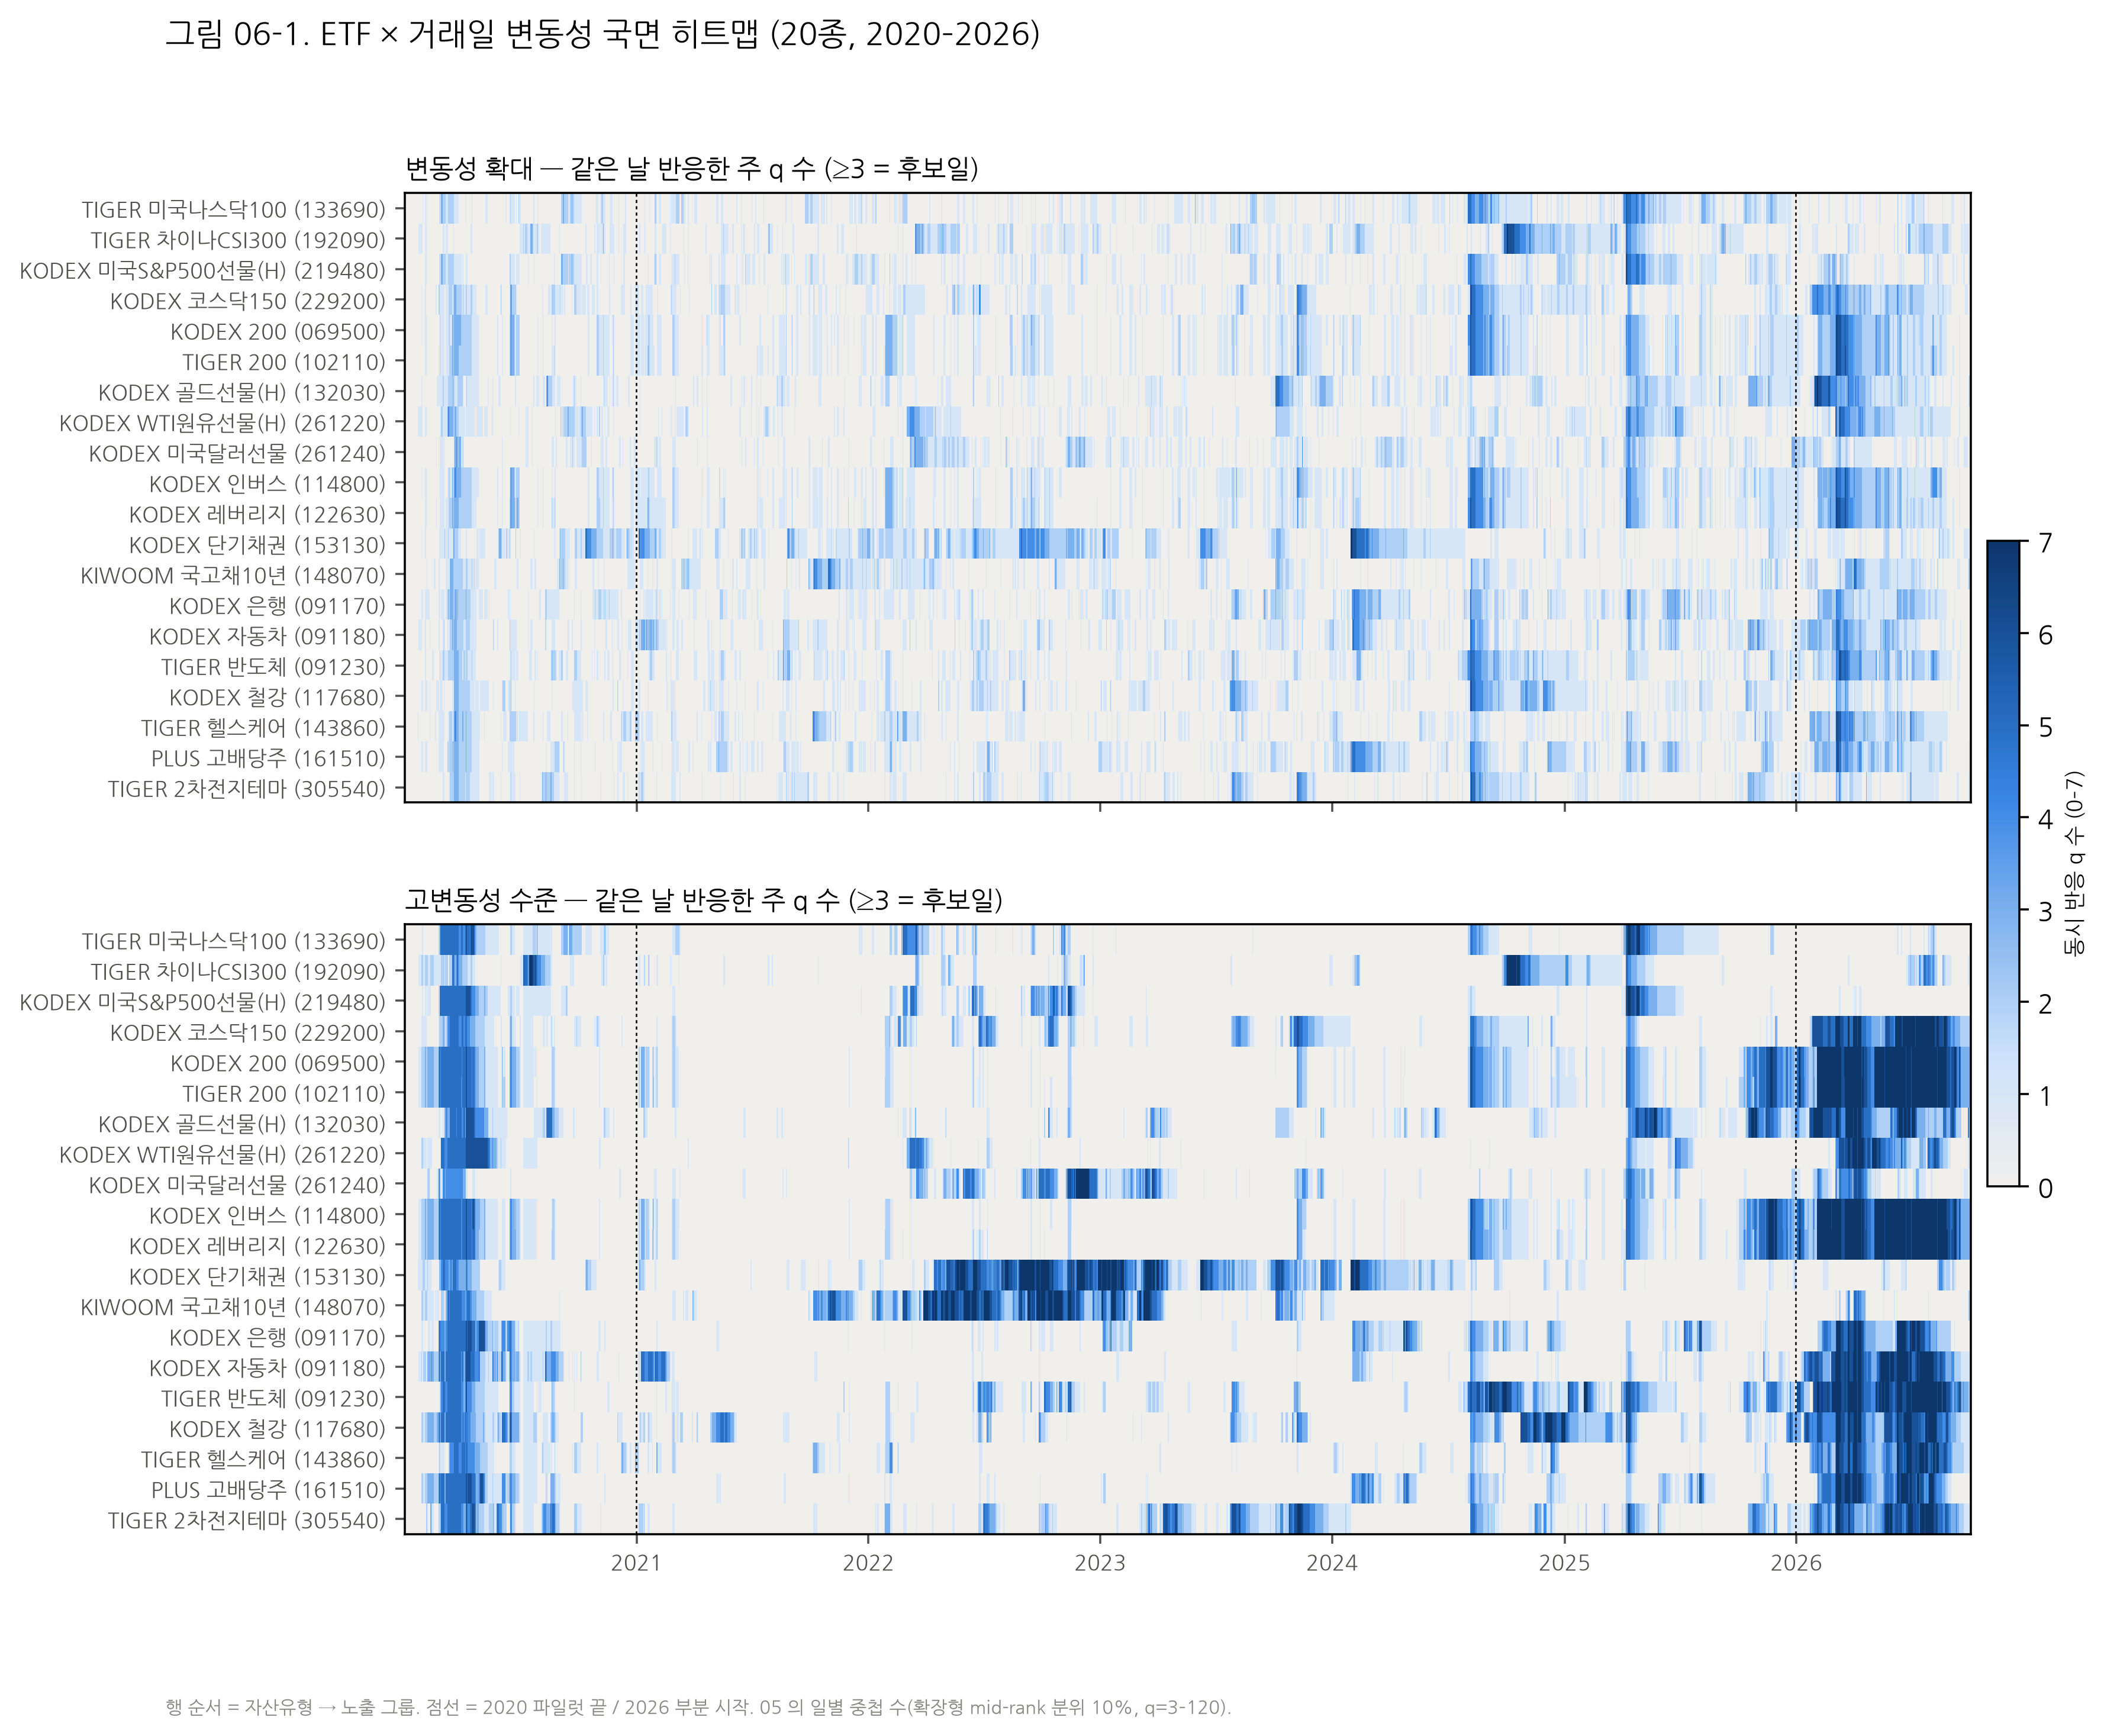

,year,year_status,channel,etf_equal_share,group_equal_share
0,2019,REFERENCE_ONLY,EXPANSION,0.000,0.000
1,2019,REFERENCE_ONLY,HIGH_LEVEL,0.000,0.000
2,2020,PILOT,EXPANSION,0.033,0.030
3,2020,PILOT,HIGH_LEVEL,0.217,0.211
4,2021,PRIMARY,EXPANSION,0.014,0.016
5,2021,PRIMARY,HIGH_LEVEL,0.023,0.024
6,2022,PRIMARY,EXPANSION,0.029,0.030
7,2022,PRIMARY,HIGH_LEVEL,0.142,0.168
8,2023,PRIMARY,EXPANSION,0.028,0.029
9,2023,PRIMARY,HIGH_LEVEL,0.100,0.113


,cat_broad_market,cat_commodity,cat_currency,cat_leveraged_inverse,cat_money_market,cat_rates,cat_sector,cat_strategy,cat_theme
year,,,,,,,,,
2020,0.20,0.22,0.12,0.25,0.15,0.14,0.25,0.29,0.28
2021,0.01,0.00,0.00,0.02,0.01,0.17,0.04,0.00,0.00
2022,0.09,0.05,0.39,0.00,0.72,0.81,0.04,0.00,0.08
2023,0.04,0.02,0.20,0.03,0.60,0.31,0.04,0.00,0.38
2024,0.09,0.02,0.00,0.09,0.19,0.00,0.17,0.17,0.11
2025,0.16,0.21,0.10,0.29,0.00,0.00,0.13,0.06,0.18
2026,0.48,0.62,0.25,0.95,0.03,0.09,0.79,0.70,0.82


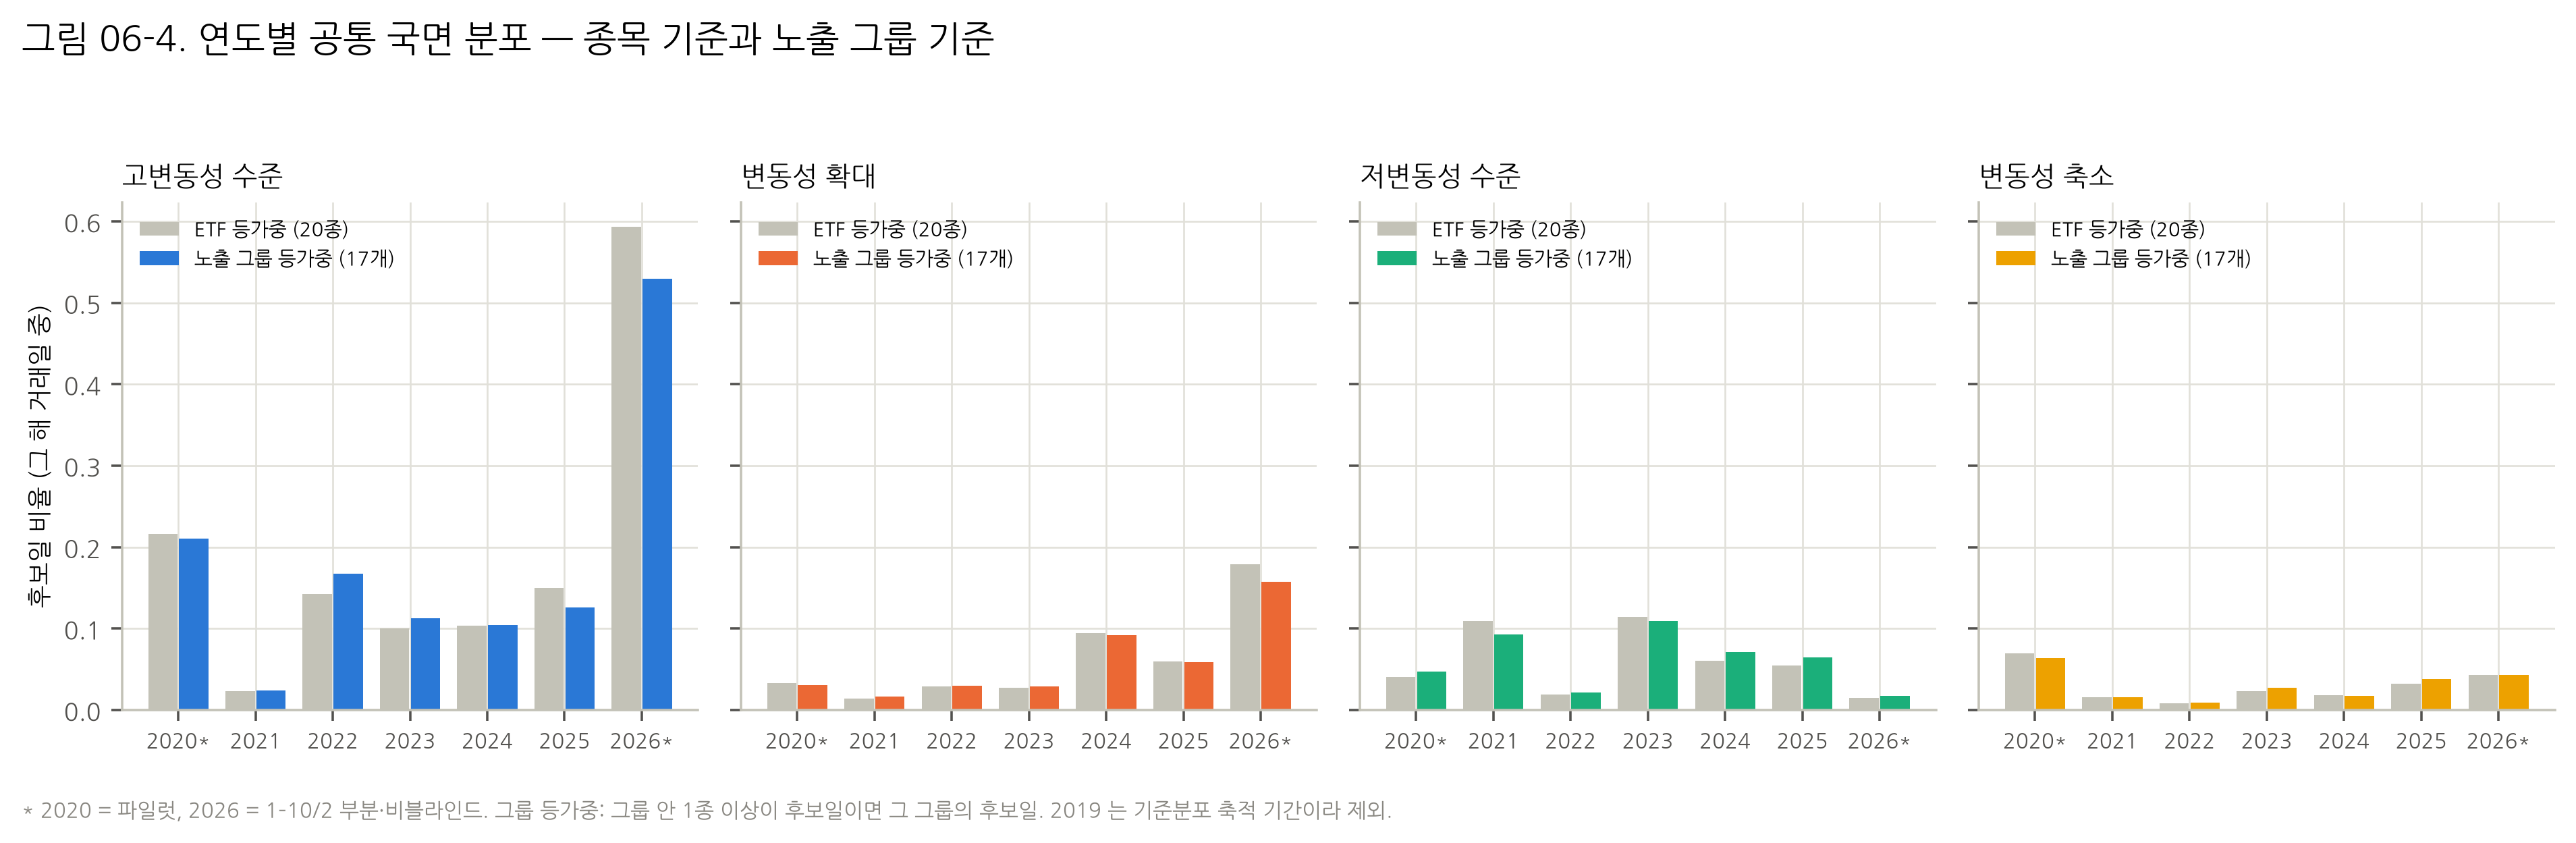

In [8]:
# 그림 06-1 (ETF × 거래일) 과 06-4 (연도별 후보일 비율, ETF 등가중 대 그룹 등가중).
FIG_FILES += F.etf_day_heatmap(OV, EXPO, FIG, "06-1")  # 그림 06-1
display(Image(filename=str(FIG_FILES[-2]), width=950))  # 표시
YS = S06["yearly_summary"]  # 연도 요약
display(YS[YS.channel.isin(["HIGH_LEVEL", "EXPANSION"])][["year", "year_status", "channel", "etf_equal_share", "group_equal_share"]].round(3).reset_index(drop=True))  # 등가중 비교
cat_cols = [c for c in YS.columns if c.startswith("cat_")]  # 자산유형 열
display(YS[(YS.channel == "HIGH_LEVEL") & YS.year.between(2020, 2026)].set_index("year")[cat_cols].round(2))  # 자산유형별 고변동성 후보일 비율
FIG_FILES += F.yearly_bars(YS, FIG, "06-4")  # 그림 06-4
display(Image(filename=str(FIG_FILES[-2]), width=950))  # 표시

**해석 (그림 06-1·06-4).**
- **고변동성 수준.** 2021–2025 에서 후보일 비율(노출 그룹 등가중)이 가장 높은 해는 2022(0.168)다.
  - 2022 의 높은 비율은 채권·통화 유형이 끌어올렸다 (위 자산유형 표).
  - 2026 부분 연도는 0.529 로 2021–2025 의 어느 해보다 3배 이상 높다.
- **확대.** 2021–2025 중에는 2024 가 가장 높다 (그룹 등가중 0.092). 2024-08 사건의 영향이다.
- **두 가중 방식의 차이는 작다.**
  - 대부분 연도에서 0.01 안쪽이다.
  - 예외는 고변동성 2022(ETF 0.142 대 그룹 0.168)와 2025(0.150 대 0.126)다.
  - 2022 는 KOSPI200 4종의 고변동성 후보일 비율이 0 이었던 해다. 그래서 4종을 1개로 줄이면 '후보 아님' 의 무게가 줄어 비율이 오른다.
  - 2025 는 반대로 4종이 함께 후보였던 날이 많아(0.288), 1개로 줄이면 비율이 내려간다.

## 8. 종목 기준과 노출 그룹 기준 순위 비교, 미국 주식 묶음 민감도

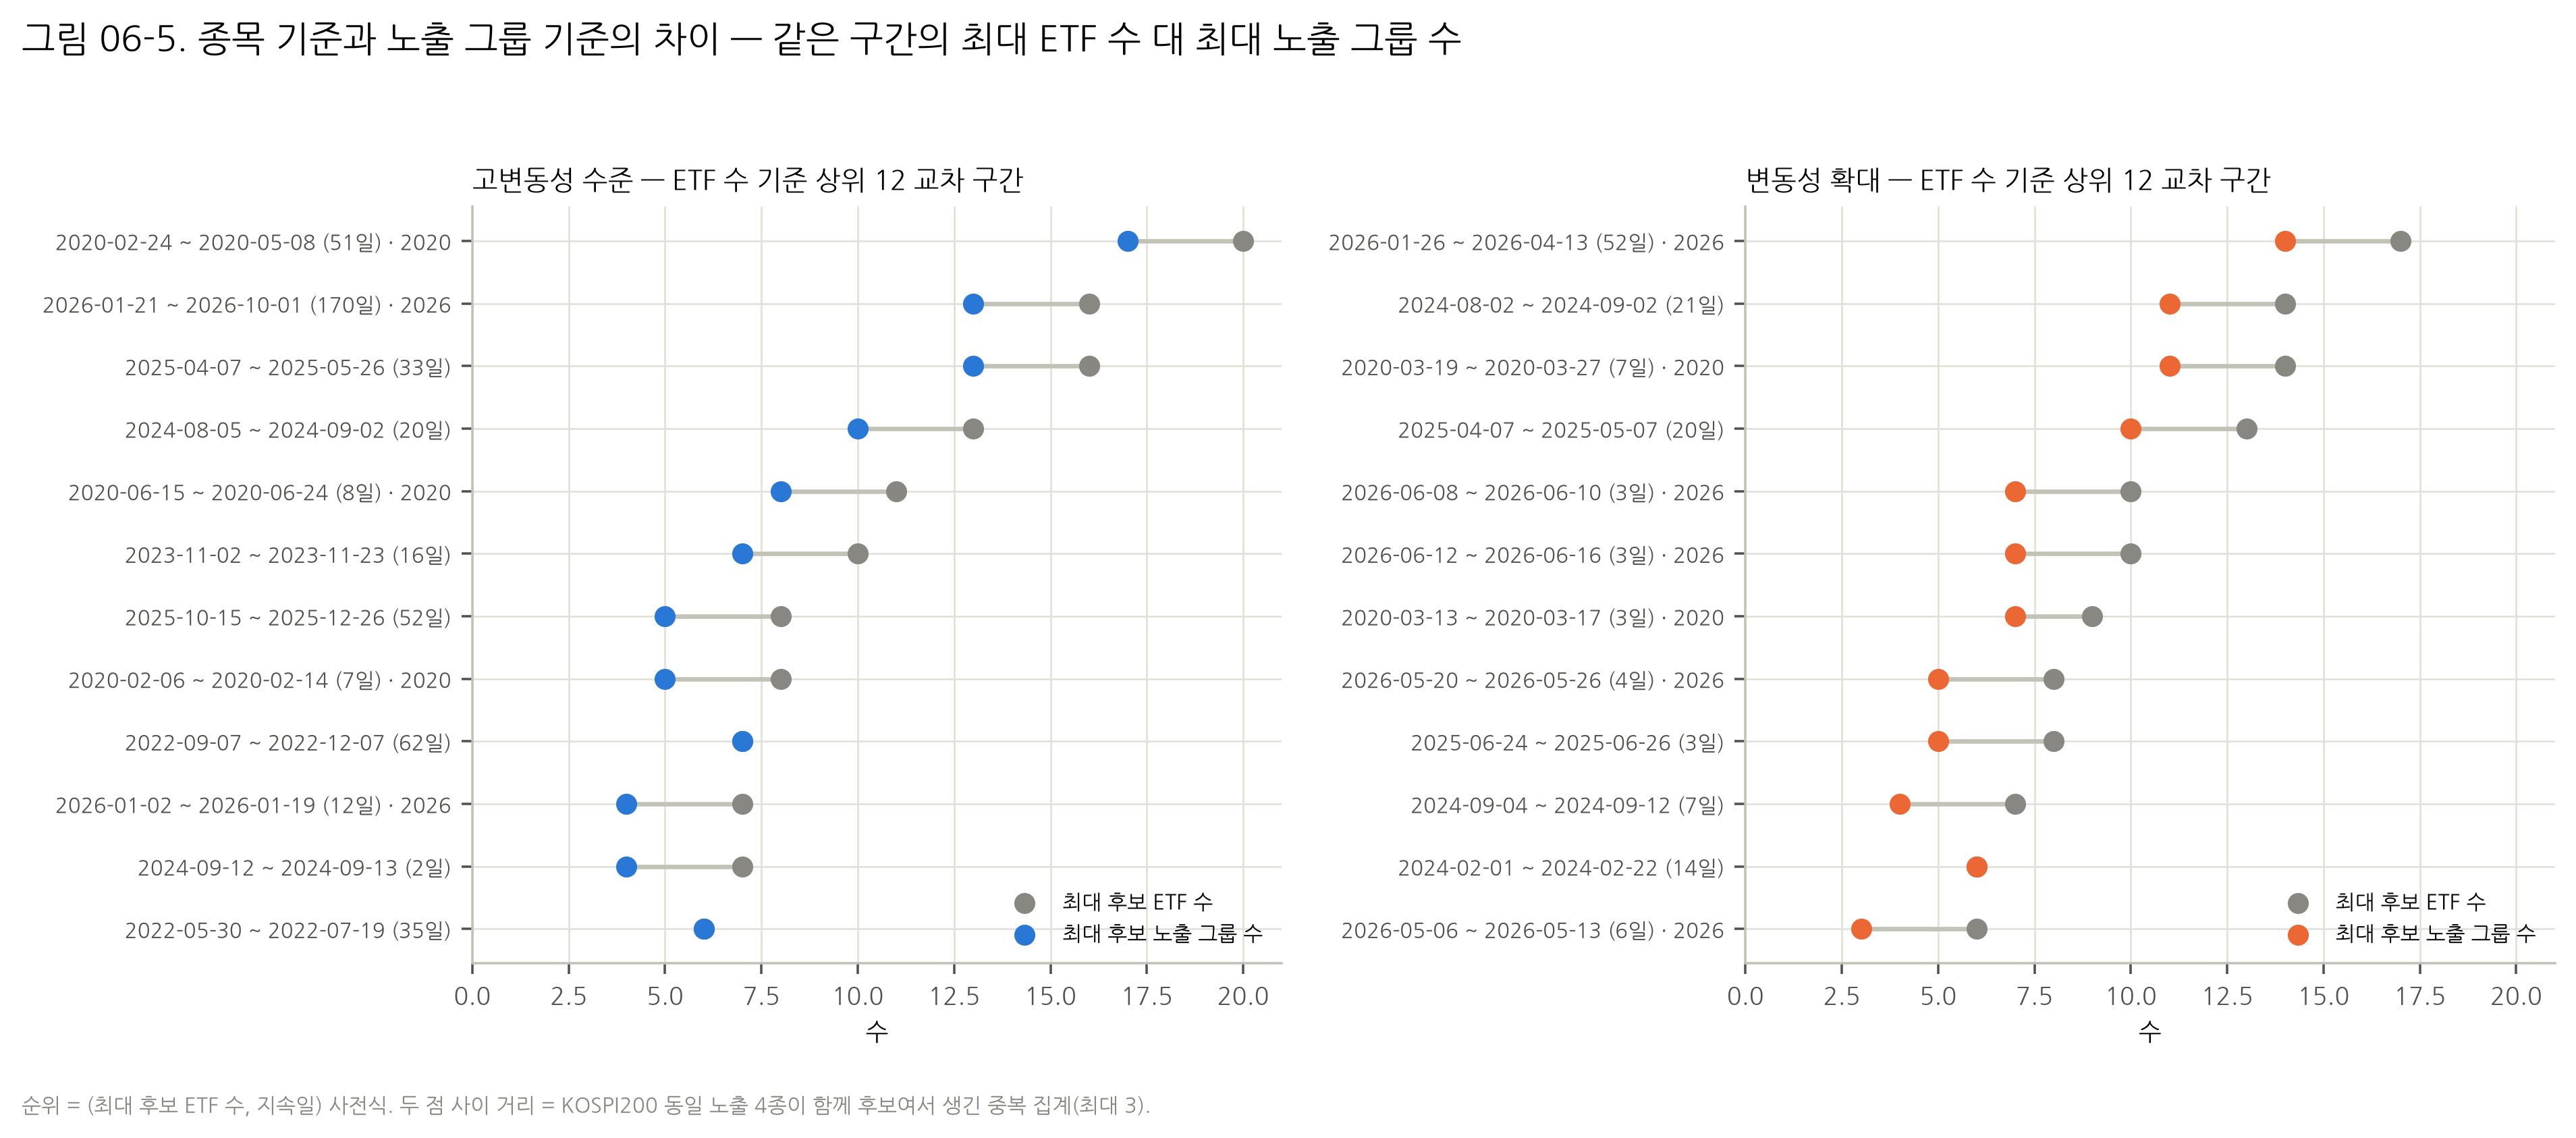

,주(17그룹),미국 2종 묶음(16그룹),종목 기준(20)
channel,,,
CONTRACTION,17,16,25
EXPANSION,23,24,25
HIGH_LEVEL,46,48,47
LOW_LEVEL,43,41,45


In [9]:
# 그림 06-5: 종목 기준 상위 교차 구간에서 최대 ETF 수와 최대 그룹 수의 차이. 미국 2종 묶음 민감도 개수.
FIG_FILES += F.rank_basis_compare(CE, FIG, "06-5")  # 그림 06-5
display(Image(filename=str(FIG_FILES[-2]), width=950))  # 표시
CU = S06["cross_intervals_group_us_sensitivity"]  # 미국 묶음 16개 그룹 기준
sens = pd.concat({"주(17그룹)": CG[CG.year_status == "PRIMARY"].groupby("channel").size(), "미국 2종 묶음(16그룹)": CU[CU.year_status == "PRIMARY"].groupby("channel").size(), "종목 기준(20)": CE[CE.year_status == "PRIMARY"].groupby("channel").size()}, axis=1)  # 2021–25 개수
display(sens)  # 기준별 교차 공통 구간 수

**해석 (그림 06-5).**
- 종목 기준 상위 12개 구간의 대부분(고변동성 10/12, 확대 10/12)은 최대 ETF 수가 최대 그룹 수보다 3 크다. KOSPI200 4종이 함께 후보여서 1개로 줄어든 차이다.
- 차이가 0 인 구간은 KOSPI200 이 빠진 공통 국면이다. 2022 채권·통화 구간이 그 예다.
- 2021–2025 교차 공통 구간 수는 기준에 따라 조금 달라진다.
  - 고변동성: 46(주) / 48(미국 묶음) / 47(종목 기준)
  - 확대: 23 / 24 / 25
  - 노출을 어떻게 묶느냐가 '몇 개의 공통 구간' 이라는 숫자를 바꾼다. 그러나 상위 사건의 정체(2024-08·2025-04·2022 채권 국면)는 바꾸지 않는다.

## 9. 20종 전체 중첩 순위 — ETF 공통 구간을 한 표로

05 의 ETF 별 공통 구간을 채널별로 합쳐 같은 키로 다시 순위를 매긴다. 각 구간에는 같은 기간 최대 후보 그룹 수와, 그룹 기준 교차 공통 구간과의 겹침 여부를 붙인다.

In [10]:
# 20종 전체 순위표와 '개별 사건 대 공통 사건' 구분.
GL = S06["global_interval_rank"]  # 전 ETF 공통 구간 + 전체 순위 + 교차 주석
show = ["ticker", "name", "channel", "interval_start", "interval_end", "duration_trading_days", "max_overlap_count", "rank_global_channel", "rank_in_etf_channel", "year_status", "max_n_group_during", "overlaps_cross_group_interval"]  # 표 열
for ch in ("HIGH_LEVEL", "EXPANSION"):  # 두 주 채널
    display(GL[(GL.channel == ch) & (GL.year_status == "PRIMARY")].head(10)[show].reset_index(drop=True))  # 2021–25 시작 상위 10 (전체 순위 유지)
share = GL[GL.year_status == "PRIMARY"].groupby("channel").overlaps_cross_group_interval.mean().round(3)  # 교차 공통과 겹친 비율
display(share.to_frame("그룹 기준 교차 공통 구간과 겹친 ETF 구간 비율 (2021–25)"))  # 표

,ticker,name,channel,interval_start,interval_end,duration_trading_days,max_overlap_count,rank_global_channel,rank_in_etf_channel,year_status,max_n_group_during,overlaps_cross_group_interval
0,153130,KODEX 단기채권,HIGH_LEVEL,2022-08-24,2023-02-27,127,7,7,1,PRIMARY,7,True
1,148070,KIWOOM 국고채10년,HIGH_LEVEL,2022-03-28,2022-08-02,89,7,8,1,PRIMARY,6,True
2,153130,KODEX 단기채권,HIGH_LEVEL,2022-04-14,2022-08-22,89,7,8,2,PRIMARY,6,True
3,148070,KIWOOM 국고채10년,HIGH_LEVEL,2022-08-16,2022-12-06,77,7,12,2,PRIMARY,7,True
4,117680,KODEX 철강,HIGH_LEVEL,2024-10-24,2025-01-22,62,7,20,3,PRIMARY,6,True
5,091230,TIGER 반도체,HIGH_LEVEL,2024-08-02,2024-10-28,55,7,22,2,PRIMARY,10,True
6,069500,KODEX 200,HIGH_LEVEL,2025-10-15,2025-12-26,52,7,24,2,PRIMARY,5,True
7,114800,KODEX 인버스,HIGH_LEVEL,2025-10-15,2025-12-26,52,7,24,2,PRIMARY,5,True
8,102110,TIGER 200,HIGH_LEVEL,2025-10-27,2025-12-26,44,7,27,2,PRIMARY,5,True
9,122630,KODEX 레버리지,HIGH_LEVEL,2025-10-27,2025-12-26,44,7,27,2,PRIMARY,5,True


,ticker,name,channel,interval_start,interval_end,duration_trading_days,max_overlap_count,rank_global_channel,rank_in_etf_channel,year_status,max_n_group_during,overlaps_cross_group_interval
0,192090,TIGER 차이나CSI300,EXPANSION,2024-09-27,2024-11-14,32,7,4,1,PRIMARY,3,True
1,153130,KODEX 단기채권,EXPANSION,2024-01-30,2024-03-14,30,7,6,1,PRIMARY,6,True
2,091230,TIGER 반도체,EXPANSION,2024-08-01,2024-08-30,21,6,10,2,PRIMARY,11,True
3,069500,KODEX 200,EXPANSION,2024-08-02,2024-09-02,21,6,10,2,PRIMARY,11,True
4,102110,TIGER 200,EXPANSION,2024-08-02,2024-09-02,21,6,10,2,PRIMARY,11,True
5,229200,KODEX 코스닥150,EXPANSION,2024-08-05,2024-09-03,21,6,10,1,PRIMARY,11,True
6,133690,TIGER 미국나스닥100,EXPANSION,2025-04-04,2025-05-07,21,6,10,1,PRIMARY,10,True
7,219480,KODEX 미국S&P500선물(H),EXPANSION,2025-04-07,2025-05-08,21,6,10,1,PRIMARY,10,True
8,117680,KODEX 철강,EXPANSION,2024-08-05,2024-09-02,20,6,16,1,PRIMARY,11,True
9,122630,KODEX 레버리지,EXPANSION,2024-08-02,2024-08-29,19,6,18,2,PRIMARY,11,True


,그룹 기준 교차 공통 구간과 겹친 ETF 구간 비율 (2021–25)
channel,
CONTRACTION,0.229
EXPANSION,0.518
HIGH_LEVEL,0.776
LOW_LEVEL,0.686


**해석.**
- 2021–2025 의 ETF 별 고변동성 공통 구간 가운데 77.6% 는 그룹 기준 교차 공통 구간과 날짜가 겹친다. 확대는 51.8%, 저변동성 68.6%, 축소 22.9% 다.
- 고변동성 상태는 여러 시장이 함께 겪는 경우가 많다. 반면 변동성 **축소**는 종목마다 따로 일어나는 경우가 대부분이다.
- 이 비율은 '공통 충격의 비중' 추정치가 아니다. 지속성이 긴 채널일수록 우연히 겹칠 기회가 많기 때문이다.

## 10. 공통 구간 순위·해석·한계 — 가설 H4 판정

In [11]:
# 주장–근거 대조: 본문 수치를 결과에서 다시 계산해 확인한다.
PRI = lambda d: d[d.year_status == "PRIMARY"]  # 2021–25 필터
exp_top = PRI(CG[CG.channel == "EXPANSION"]).head(2)  # 2021–25 확대 상위 2
CLAIMS = {  # 본문 수치
    # 본문 주장 (계산값, 본문값)
    "2021–25 그룹 기준 교차 구간 HIGH/EXP/LOW/CON": (tuple(PRI(CG).groupby("channel").size().reindex(["HIGH_LEVEL", "EXPANSION", "LOW_LEVEL", "CONTRACTION"])), (46, 23, 43, 17)),
    # 본문 주장 (계산값, 본문값)
    "확대 상위 2 (시작, 그룹 수)": (tuple(zip(exp_top.interval_start, exp_top.max_count, strict=True)), (("2024-08-02", 11), ("2025-04-07", 10))),
    # 본문 주장 (계산값, 본문값)
    "KOSPI200 쌍 Jaccard 범위 HIGH": ((round(WJ[WJ.channel == "HIGH_LEVEL"].jaccard.min(), 2), round(WJ[WJ.channel == "HIGH_LEVEL"].jaccard.max(), 2)), (0.93, 0.99)),
    # 본문 주장 (계산값, 본문값)
    "KOSPI200 쌍 Jaccard 범위 EXP": ((round(WJ[WJ.channel == "EXPANSION"].jaccard.min(), 2), round(WJ[WJ.channel == "EXPANSION"].jaccard.max(), 2)), (0.75, 0.93)),
    # 본문 주장 (계산값, 본문값)
    "차이나 2024-09 확대 구간의 최대 그룹 수": (int(GL[(GL.ticker == "192090") & (GL.channel == "EXPANSION") & (GL.interval_start == "2024-09-27")].max_n_group_during.iloc[0]), 3),
    # 본문 주장 (계산값, 본문값)
    "2022 고변동성 그룹 등가중 비율": (round(float(YS[(YS.year == 2022) & (YS.channel == "HIGH_LEVEL")].group_equal_share.iloc[0]), 3), 0.168),
    # 본문 주장 (계산값, 본문값)
    "2026 고변동성 그룹 등가중 비율": (round(float(YS[(YS.year == 2026) & (YS.channel == "HIGH_LEVEL")].group_equal_share.iloc[0]), 3), 0.529),
    # 본문 주장 (계산값, 본문값)
    "교차 겹침 비율 HIGH/EXP/LOW/CON": (tuple(share.reindex(["HIGH_LEVEL", "EXPANSION", "LOW_LEVEL", "CONTRACTION"])), (0.776, 0.518, 0.686, 0.229)),
    # 본문 주장 (계산값, 본문값)
    "민감도 개수 HIGH (주, 미국묶음, 종목)": (tuple(sens.loc["HIGH_LEVEL"].astype(int)), (46, 48, 47)),
    # 본문 주장 (계산값, 본문값)
    "KOSPI200 4종 2022 고변동성 후보일 비율": (round(float(OV[OV.ticker.isin(CFG["exposure_kospi200"]) & (OV.channel == "HIGH_LEVEL") & (OV.date.dt.year == 2022)].overlap_candidate_day.mean()), 3), 0.0),
    # 본문 주장 (계산값, 본문값)
    "종목 기준 상위 12 중 ETF−그룹 = 3 인 구간 수 (HIGH, EXP)": (tuple(int((d.max_n_etf - d.max_n_group).eq(3).sum()) for d in (CE[CE.channel == c].sort_values(["rank_in_channel", "interval_start"]).head(12) for c in ("HIGH_LEVEL", "EXPANSION"))), (10, 10)),
    # 본문 주장 (계산값, 본문값)
    "2022-09 고변동성 교차 구간에 KOSPI200 없음": ("KOSPI200_동일노출" not in CG[(CG.channel == "HIGH_LEVEL") & (CG.interval_start == "2022-09-07")].groups_ever.iloc[0], True),
}  # 끝
for k, (got, want) in CLAIMS.items():  # 하나씩
    assert got == want, f"{k}: 계산 {got} ≠ 본문 {want}"  # 불일치면 중단
    print(f"✓ {k}: {got}")  # 확인

✓ 2021–25 그룹 기준 교차 구간 HIGH/EXP/LOW/CON: (46, 23, 43, 17)
✓ 확대 상위 2 (시작, 그룹 수): (('2024-08-02', 11), ('2025-04-07', 10))
✓ KOSPI200 쌍 Jaccard 범위 HIGH: (np.float64(0.93), np.float64(0.99))
✓ KOSPI200 쌍 Jaccard 범위 EXP: (np.float64(0.75), np.float64(0.93))
✓ 차이나 2024-09 확대 구간의 최대 그룹 수: 3
✓ 2022 고변동성 그룹 등가중 비율: 0.168
✓ 2026 고변동성 그룹 등가중 비율: 0.529
✓ 교차 겹침 비율 HIGH/EXP/LOW/CON: (0.776, 0.518, 0.686, 0.229)
✓ 민감도 개수 HIGH (주, 미국묶음, 종목): (46, 48, 47)
✓ KOSPI200 4종 2022 고변동성 후보일 비율: 0.0
✓ 종목 기준 상위 12 중 ETF−그룹 = 3 인 구간 수 (HIGH, EXP): (10, 10)
✓ 2022-09 고변동성 교차 구간에 KOSPI200 없음: True


| | 지지하는 관찰 | 지지하지 않는·제한하는 관찰 |
|---|---|---|
| **H4** 노출 군집 공통 변화 | 같은 노출(KOSPI200 4종)은 후보일 Jaccard 0.75–0.99 로 거의 같은 구간을 가진다. 노출이 다른 ETF 사이에도 2024-08 (11/17 그룹)·2025-04 (10/17) 확대, 2022 채권·통화 주도 고변동성(6–7 그룹) 같은 공통 구간이 있다 | 노출이 다른 쌍의 일치도 중앙값은 0.09–0.18 로 낮다. 다중 기간으로 가장 강한 확대 중 하나(차이나 2024-09)는 개별 사건이다. 축소 구간은 77% 가 교차 공통과 겹치지 않는다. 의존을 보존한 귀무보정이 없으므로 '유의한 공통성' 이 아니다 |

**대안 설명.**
1. **같은 달력 효과.** 모든 ETF 는 같은 거래일과 같은 기준분포 시작일(2019-01)을 공유한다. 기준분포에 들어간 시기가 같으므로 분위가 같은 방향으로 움직일 수 있다. 예: 2019–2020 이 조용했던 자산은 2022 에 일제히 '높음' 으로 보인다.
2. **지속성.** 고변동성 상태는 수개월 지속된다. 그래서 독립인 두 계열도 우연히 겹치는 날이 많다. 확대보다 고변동성의 교차 겹침 비율이 높은 것(77.6% 대 51.8%)은 이 효과와 구별되지 않는다.
3. **노출 정의.** 미국 주식 2종을 묶으면 개수가 바뀐다. 상관 기반 군집을 쓰면 더 바뀔 수 있다. 이번에는 전체 기간 상관으로 사후 군집을 만들지 않았다.

**반증 가능성.** 각 ETF 의 후보일 열을 연도 안에서 원형 이동해 자기 지속성은 보존하고 동시성만 해체하면, 교차 공통 구간 수의 귀무분포를 만들 수 있다. 관측 수가 그 분포 안에 있다면 '공통성' 은 지속성으로 설명된다. 이 검정은 W2-lock-1 범위 밖이다. 후속 연구에서 사전 등록 후 수행한다.

## 11. 07 로 전달할 구간 계약

In [12]:
# 06→07 인계: 05·06 결과 해시, 07 이 쓸 구간 표(전체 순위·교차 주석 포함)와 노출 정의.
fig_index = pd.DataFrame({"file": [str(p.relative_to(BASE)) for p in FIG_FILES], "sha256": [sha256(p) for p in FIG_FILES]})  # 그림 해시
fig_index.to_csv(BASE / "results/06/figure_index_06.csv", index=False)  # 그림 색인
MAN6 = S06["manifest"]  # 06 결과 해시
handoff = {"from": "06", "to": "07", "protocol_version": CFG["protocol_version"], "config_sha256": FREEZE[0][0], "contract_sha256": FREEZE[1][0], "environment": ACTUAL_ENV, "results": {**H05["results"], **MAN6["files_sha256"]}, "work_files": H05["work_files"], "figure_index_sha256": sha256(BASE / "results/06/figure_index_06.csv"), "interval_table_for_07": "results/06/global_interval_rank.csv", "exposure_table_for_07": "results/06/exposure_groups.csv"}  # 인계 내용
(BASE / "results/06_to_07.json").write_text(json.dumps(handoff, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")  # 저장
display(pd.Series(MAN6["files_sha256"]).rename("sha256").to_frame())  # 06 결과 해시
print("그림", len(FIG_FILES) // 2, "개 · 인계 파일:", BASE / "results/06_to_07.json")  # 요약

,sha256
results/06/exposure_groups.csv,2fd8a4cc777bf0967967abbb73ac3b1e91926c8d2d5a50...
results/06/cross_daily_counts.csv,db0a7d32ec3774d384f5aca445473cbf0ef559ae16fe6c...
results/06/cross_intervals_group.csv,6cb7e983d5ee61de3cf37e67170b690dad81ee04d63e6a...
results/06/cross_intervals_etf.csv,f953e648e706363ff83a888ce91e0c78a5c252f466f720...
results/06/cross_intervals_group_us_sensitivity.csv,013a1e0f8dfd865393d9fe40129a3ae795f8fa1c5b8868...
results/06/within_group_intervals.csv,33d15371f79bee529273ff981020d51b83e95b84bf9535...
results/06/within_group_pair_jaccard.csv,7e6b0f7ef0f8198c2e94276f692688b262f106ee6a5bd0...
results/06/all_pair_jaccard.csv,05bffbd1f164c96d2fb286e4edd158341860abd070d79e...
results/06/yearly_summary.csv,d67ce697368ff63e5b413a2464a6a869df64377fa6000c...
results/06/global_interval_rank.csv,a57efcce31dc3e28336802bc50a2e64c6de420e6819a16...


그림 5 개 · 인계 파일: /home/sieg/projects-wsl/hongik_univ_26_2/SA/1017/R2H_MultiHorizon_Volatility_Regime/research/multihorizon_w2/results/06_to_07.json


**07 에 넘기는 것.**
- `global_interval_rank.csv`: 05 의 ETF 별 공통 구간 전부. ETF 범위·전체 순위, 같은 기간 최대 그룹 수, 교차 공통 겹침 여부가 붙어 있다.
- `exposure_groups.csv`: 노출 그룹과 명목 배수.
- 07 은 이 구간들의 **가격 반응**과 **같은 날짜 다른 ETF 대비 상대 움직임**을 본다.

**넘기지 않는 것.** 구간을 '급등' 이나 '구조변화' 의 정답으로 쓰는 해석이다. 구간은 분산 분위 규칙으로 만든 탐색 후보다.